In [2]:
# Importação de Bibliotecas Essenciais (PEP 8)
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)
import joblib
import cv2

# Configuração visual padrão para gráficos técnicos
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid", palette="deep")
print("Ambiente inicializado com sucesso!")

Ambiente inicializado com sucesso!


In [12]:
# 1.1 Carregamento e Inspeção Estrutural do Dataset
df_raw = pd.read_csv('dados_sensores_aeromotion.csv')
df = df_raw.copy()
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

print(f"Dimensões do Dataset: {df.shape}")
print("\nTipos de Dados:")
print(df.dtypes)

# Verificação de consistência dos intervalos temporais (delta = 10 minutos)
deltas = df['timestamp'].diff().dropna()
print("\nConsistência de Timestamps (Intervalos Globais):")
print(deltas.value_counts())

# Quantificação da taxa de ausência de dados (%) agrupada por equipamento
sensores_com_nan = ['temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'emissao_acustica_db']
taxa_ausencia_pct = df.groupby('id_equipamento')[sensores_com_nan].apply(lambda x: x.isnull().mean() * 100).round(2)
contagem_ausencia = df.groupby('id_equipamento')[sensores_com_nan].apply(lambda x: x.isnull().sum())

print("\nContagem de Dados Ausentes (NaN) por Equipamento:")
print(contagem_ausencia)
print("\nTaxa de Ausência (%) por Equipamento:")
print(taxa_ausencia_pct)

Dimensões do Dataset: (12000, 11)

Tipos de Dados:
timestamp                    datetime64[us]
id_equipamento                          str
modo_operacao                           str
horas_operacao_acumuladas           float64
temperatura_mancal_c                float64
vibracao_rms_mms                    float64
pressao_oleo_bar                    float64
rotacao_rpm                         float64
emissao_acustica_db                 float64
corrente_eletrica_amp               float64
tipo_falha                            int64
dtype: object

Consistência de Timestamps (Intervalos Globais):
timestamp
0 days 00:10:00    11999
Name: count, dtype: int64

Contagem de Dados Ausentes (NaN) por Equipamento:
                temperatura_mancal_c  vibracao_rms_mms  pressao_oleo_bar  \
id_equipamento                                                             
TURB-101                          85                91                84   
TURB-102                         106                83       

In [4]:
# 1.2 Identificação e Tratamento de Outliers (Interferência Eletromagnética) e Interpolação por Equipamento
df = df.sort_values(['id_equipamento', 'timestamp']).reset_index(drop=True)

# Detecção por limites operacionais físicos e Z-Score móvel
mask_outlier_temp = (df['temperatura_mancal_c'] > 150.0) | (df['temperatura_mancal_c'] < 20.0)
mask_outlier_vib = (df['vibracao_rms_mms'] < 0.0) | (df['vibracao_rms_mms'] > 30.0)

print(f"Anomalias eletromagnéticas em Temperatura (999.9°C): {mask_outlier_temp.sum()} registros")
print(f"Anomalias eletromagnéticas em Vibração (-99.0 mm/s): {mask_outlier_vib.sum()} registros")

# Substituição dos ruídos por NaN para posterior interpolação física contínua
df.loc[mask_outlier_temp, 'temperatura_mancal_c'] = np.nan
df.loc[mask_outlier_vib, 'vibracao_rms_mms'] = np.nan

# Interpolação temporal linear por equipamento (respeitando a continuidade física de cada turbina)
colunas_sensores = [
    'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar',
    'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp'
]

for col in colunas_sensores:
    df[col] = df.groupby('id_equipamento')[col].transform(
        lambda s: s.interpolate(method='linear').bfill().ffill()
    )

print(f"Total de NaNs remanescentes após interpolação por bancada: {df[colunas_sensores].isnull().sum().sum()}")
print("\nEstatísticas Descritivas Pós-Saneamento:")
print(df[colunas_sensores].describe().round(2))

Anomalias eletromagnéticas em Temperatura (999.9°C): 58 registros
Anomalias eletromagnéticas em Vibração (-99.0 mm/s): 45 registros
Total de NaNs remanescentes após interpolação por bancada: 0

Estatísticas Descritivas Pós-Saneamento:
       temperatura_mancal_c  vibracao_rms_mms  pressao_oleo_bar  rotacao_rpm  \
count              12000.00          12000.00          12000.00     12000.00   
mean                  64.02              3.41              4.23      3031.15   
std                    9.85              2.27              0.58       383.23   
min                   40.00              0.08              0.68      2278.20   
25%                   58.10              2.20              3.96      2950.30   
50%                   63.12              2.71              4.24      3010.50   
75%                   69.52              3.72              4.60      3461.50   
max                  119.60             15.17              5.59      3641.40   

       emissao_acustica_db  corrente_eletric

In [5]:
# 1.3 Criação de Rolling Features (1h = 6 passos, 6h = 36 passos) por Equipamento e Severidade Dinâmica
df = df.sort_values(['id_equipamento', 'timestamp']).reset_index(drop=True)

for col, prefix in [('vibracao_rms_mms', 'vib'), ('temperatura_mancal_c', 'temp')]:
    df[f'{prefix}_roll_mean_1h'] = df.groupby('id_equipamento')[col].transform(
        lambda s: s.rolling(window=6, min_periods=1).mean()
    )
    df[f'{prefix}_roll_std_1h'] = df.groupby('id_equipamento')[col].transform(
        lambda s: s.rolling(window=6, min_periods=1).std().fillna(0.0)
    )
    df[f'{prefix}_roll_mean_6h'] = df.groupby('id_equipamento')[col].transform(
        lambda s: s.rolling(window=36, min_periods=1).mean()
    )
    df[f'{prefix}_roll_std_6h'] = df.groupby('id_equipamento')[col].transform(
        lambda s: s.rolling(window=36, min_periods=1).std().fillna(0.0)
    )

# Feature Derivada: Severidade Dinâmica = Vibração RMS / Rotação (RPM)
df['severidade_dinamica'] = df['vibracao_rms_mms'] / df['rotacao_rpm']

# Reordenar cronologicamente para preservar a linha do tempo global
df = df.sort_values('timestamp').reset_index(drop=True)
print("Engenharia de Features concluída! Total de colunas:", df.shape[1])
print(df[['timestamp', 'id_equipamento', 'vibracao_rms_mms', 'vib_roll_mean_1h', 'temp_roll_mean_1h', 'severidade_dinamica']].head())

Engenharia de Features concluída! Total de colunas: 20
            timestamp id_equipamento  vibracao_rms_mms  vib_roll_mean_1h  \
0 2026-01-01 00:00:00       TURB-103              9.98             9.980   
1 2026-01-01 00:10:00       TURB-104              3.13             3.130   
2 2026-01-01 00:20:00       TURB-101              2.50             2.500   
3 2026-01-01 00:30:00       TURB-103              1.43             5.705   
4 2026-01-01 00:40:00       TURB-103              3.44             4.950   

   temp_roll_mean_1h  severidade_dinamica  
0             59.790             0.003319  
1             79.490             0.000897  
2             57.830             0.001049  
3             62.175             0.000474  
4             65.050             0.000970  


Médias das Variáveis por Regime Operacional (modo_operacao):
               temperatura_mancal_c  vibracao_rms_mms  pressao_oleo_bar  \
modo_operacao                                                             
Carga_Alta                  72.7758            4.4349            4.7100   
Carga_Media                 62.9829            3.1775            4.1358   
Cruzeiro                    53.3990            2.4356            3.7424   

               rotacao_rpm  emissao_acustica_db  corrente_eletrica_amp  \
modo_operacao                                                            
Carga_Alta       3500.3439              63.0692                38.6804   
Carga_Media      3000.3060              53.5098                28.6457   
Cruzeiro         2400.7890              45.6484                20.6118   

               severidade_dinamica  
modo_operacao                       
Carga_Alta                  0.0013  
Carga_Media                 0.0011  
Cruzeiro                    0.0010  

Médias

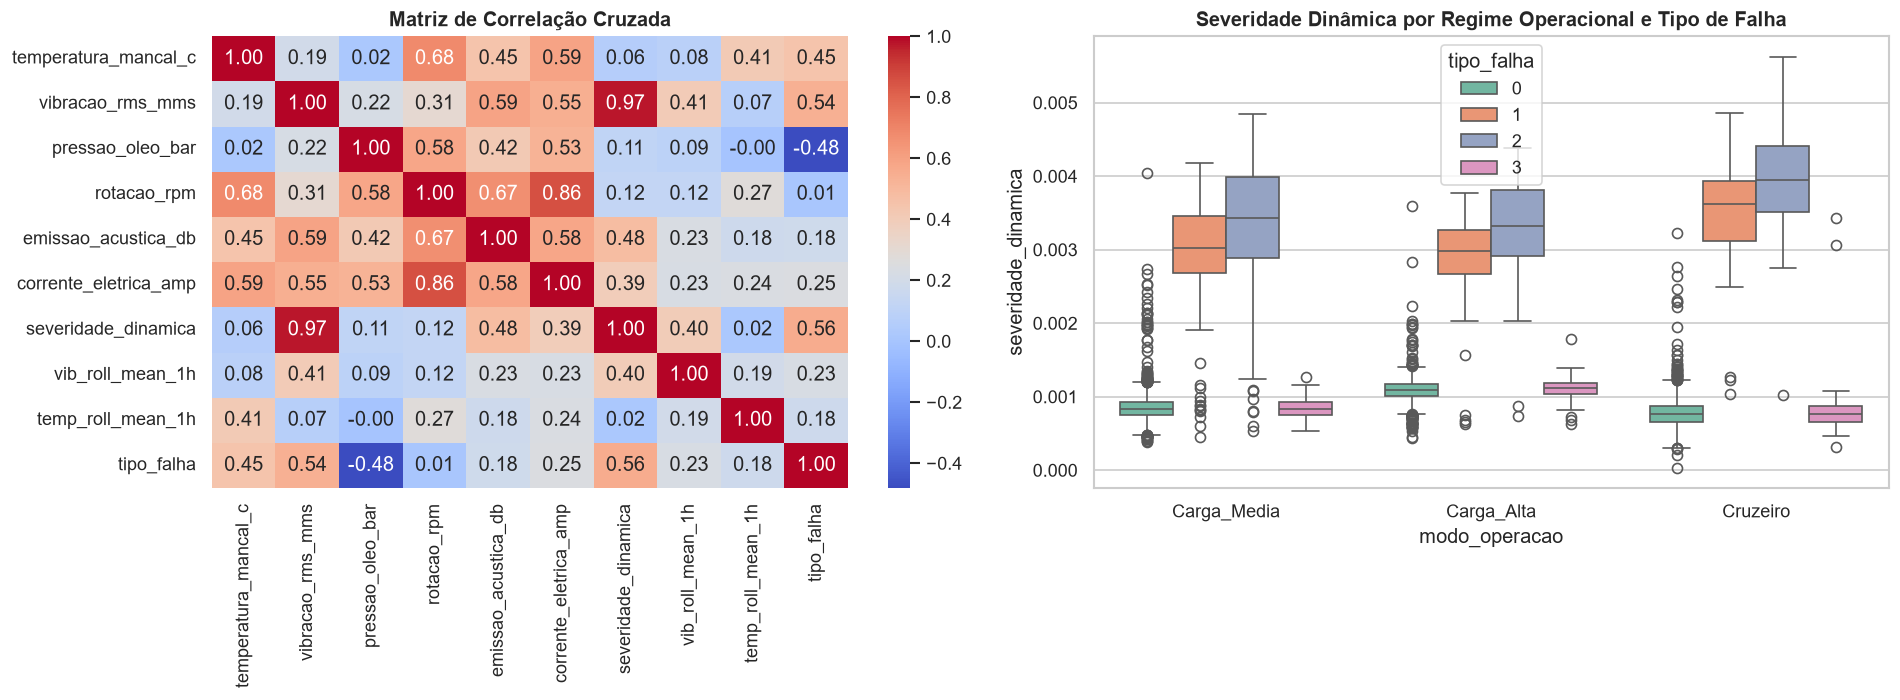

In [6]:
# 1.4 Estatísticas por Modo de Operação e Tipo de Falha + Visualizações EDA
print("Médias das Variáveis por Regime Operacional (modo_operacao):")
print(df.groupby('modo_operacao')[colunas_sensores + ['severidade_dinamica']].mean().round(4))

print("\nMédias das Variáveis por Classe de Falha (tipo_falha):")
print(df.groupby('tipo_falha')[colunas_sensores + ['severidade_dinamica']].mean().round(4))

# Plotagem da Matriz de Correlação e Severidade Dinâmica por Regime
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
corr_cols = [
    'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar',
    'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp',
    'severidade_dinamica', 'vib_roll_mean_1h', 'temp_roll_mean_1h', 'tipo_falha'
]
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Matriz de Correlação Cruzada", fontweight='bold')

sns.boxplot(data=df, x='modo_operacao', y='severidade_dinamica', hue='tipo_falha', ax=axes[1], palette='Set2')
axes[1].set_title("Severidade Dinâmica por Regime Operacional e Tipo de Falha", fontweight='bold')
plt.tight_layout()
plt.show()

In [7]:
# 2.1 Codificação Categórica, Divisão Temporal (70% Treino / 30% Teste), RobustScaler e SMOTE
df_encoded = pd.get_dummies(df, columns=['id_equipamento', 'modo_operacao'], drop_first=False, dtype=float)
feature_cols = [c for c in df_encoded.columns if c not in ['timestamp', 'tipo_falha']]

# Divisão Temporal Estrita (70% iniciais para treino, 30% finais para teste)
split_idx = int(len(df_encoded) * 0.70)
train_df = df_encoded.iloc[:split_idx].copy()
test_df = df_encoded.iloc[split_idx:].copy()

X_train = train_df[feature_cols].values
y_train = train_df['tipo_falha'].values
X_test = test_df[feature_cols].values
y_test = test_df['tipo_falha'].values

# Padronização com RobustScaler (resistente a resíduos de cauda pesada)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Reamostragem SMOTE para equilibrar as classes minoritárias no conjunto de treino
def aplicar_smote_multiclasse(X, y, k=5, random_state=42):
    try:
        from imblearn.over_sampling import SMOTE
        sm = SMOTE(k_neighbors=k, random_state=random_state)
        return sm.fit_resample(X, y)
    except ImportError:
        rng = np.random.default_rng(random_state)
        classes, counts = np.unique(y, return_counts=True)
        max_count = counts.max()
        X_res, y_res = [X], [y]
        for cls, count in zip(classes, counts):
            if count < max_count:
                n_syn = max_count - count
                X_c = X[y == cls]
                nn = NearestNeighbors(n_neighbors=min(k + 1, len(X_c))).fit(X_c)
                _, idx = nn.kneighbors(X_c)
                i_base = rng.integers(0, len(X_c), size=n_syn)
                i_neigh = rng.integers(1, idx.shape[1], size=n_syn)
                gaps = rng.random((n_syn, 1))
                syn = X_c[i_base] + gaps * (X_c[idx[i_base, i_neigh]] - X_c[i_base])
                X_res.append(syn)
                y_res.append(np.full(n_syn, cls))
        return np.vstack(X_res), np.concatenate(y_res)

X_train_smote, y_train_smote = aplicar_smote_multiclasse(X_train_scaled, y_train)
print("Distribuição original no Treino:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Distribuição pós-SMOTE no Treino:", dict(zip(*np.unique(y_train_smote, return_counts=True))))

Distribuição original no Treino: {np.int64(0): np.int64(7401), np.int64(1): np.int64(417), np.int64(2): np.int64(329), np.int64(3): np.int64(253)}
Distribuição pós-SMOTE no Treino: {np.int64(0): np.int64(7401), np.int64(1): np.int64(7401), np.int64(2): np.int64(7401), np.int64(3): np.int64(7401)}


In [8]:
# 2.2 Treinamento e Comparação de Modelos Supervisionados Multiclasse
# Modelo 1: Random Forest com GridSearchCV
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid={'n_estimators': [150, 250], 'max_depth': [12, 20], 'min_samples_split': [2, 5]},
    cv=3, scoring='f1_macro', n_jobs=-1
)
rf_grid.fit(X_train_smote, y_train_smote)
best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)

# Modelo 2: Gradient Boosting (LightGBM-style HistGradientBoosting) com RandomizedSearchCV
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    param_distributions={'max_iter': [150, 200], 'max_depth': [6, 10], 'learning_rate': [0.05, 0.1, 0.15]},
    n_iter=4, cv=3, scoring='f1_macro', random_state=42, n_jobs=-1
)
hgb_search.fit(X_train_smote, y_train_smote)
best_hgb = hgb_search.best_estimator_
y_pred_hgb = best_hgb.predict(X_test_scaled)

print("=== RELATÓRIO DE CLASSIFICAÇÃO: RANDOM FOREST (SMOTE + GridSearchCV) ===")
print(classification_report(y_test, y_pred_rf, digits=4))

print("=== RELATÓRIO DE CLASSIFICAÇÃO: GRADIENT BOOSTING (SMOTE + RandomizedSearchCV) ===")
print(classification_report(y_test, y_pred_hgb, digits=4))

=== RELATÓRIO DE CLASSIFICAÇÃO: RANDOM FOREST (SMOTE + GridSearchCV) ===
              precision    recall  f1-score   support

           0     0.9959    0.9997    0.9978      3159
           1     0.9884    0.9344    0.9607       183
           2     0.9735    0.9735    0.9735       151
           3     1.0000    0.9813    0.9906       107

    accuracy                         0.9947      3600
   macro avg     0.9895    0.9722    0.9806      3600
weighted avg     0.9947    0.9947    0.9947      3600

=== RELATÓRIO DE CLASSIFICAÇÃO: GRADIENT BOOSTING (SMOTE + RandomizedSearchCV) ===
              precision    recall  f1-score   support

           0     0.9981    1.0000    0.9991      3159
           1     1.0000    0.9672    0.9833       183
           2     0.9868    0.9868    0.9868       151
           3     1.0000    1.0000    1.0000       107

    accuracy                         0.9978      3600
   macro avg     0.9962    0.9885    0.9923      3600
weighted avg     0.9978    0.

In [9]:
# 2.3 Isolation Forest treinado exclusivamente em dados normais (tipo_falha == 0)
core_features = [
    'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar',
    'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp', 'severidade_dinamica'
]
core_idx = [feature_cols.index(c) for c in core_features]

X_train_normal_core = X_train_scaled[y_train == 0][:, core_idx]
X_test_core = X_test_scaled[:, core_idx]

iso_forest = IsolationForest(n_estimators=200, contamination=0.05, random_state=42, n_jobs=-1)
iso_forest.fit(X_train_normal_core)

iso_preds = iso_forest.predict(X_test_core) # 1 = Normal, -1 = Anomalia
especificidade_normal = (iso_preds[y_test == 0] == 1).mean()
recall_anomalias = (iso_preds[y_test != 0] == -1).mean()

print(f"Especificidade em Operação Normal (Classe 0): {especificidade_normal:.4f}")
print(f"Taxa Global de Detecção de Anomalias (Classes 1, 2 e 3): {recall_anomalias:.4f}")
for cls in [1, 2, 3]:
    print(f"  -> Recall de Anomalia para Classe {cls}: {(iso_preds[y_test == cls] == -1).mean():.4f}")

# 2.5 Exportação dos Modelos e Escalador (.joblib)
joblib.dump(best_hgb, 'modelo_multiclasse_aeromotion.joblib')
joblib.dump(best_rf, 'modelo_rf_aeromotion.joblib')
joblib.dump(iso_forest, 'modelo_isolation_forest.joblib')
joblib.dump(scaler, 'robust_scaler_aeromotion.joblib')
print("\nArtefatos exportados com sucesso (.joblib)!")

Especificidade em Operação Normal (Classe 0): 0.9471
Taxa Global de Detecção de Anomalias (Classes 1, 2 e 3): 0.9773
  -> Recall de Anomalia para Classe 1: 0.9672
  -> Recall de Anomalia para Classe 2: 0.9868
  -> Recall de Anomalia para Classe 3: 0.9813

Artefatos exportados com sucesso (.joblib)!


In [10]:
# 3.1 Pipeline OpenCV de Inspeção Geométrica (Canny + Contornos) e Térmica (HSV + Thresholding)
def inspecionar_geometria_rotor(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 1.4)
    edges = cv2.Canny(blur, threshold1=50, threshold2=150)
    edges_closed = cv2.dilate(edges, np.ones((3, 3), np.uint8), iterations=1)
    contours, _ = cv2.findContours(edges_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    c = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(c)
    perimetro = cv2.arcLength(c, True)
    circularidade = (4 * np.pi * area) / (perimetro ** 2) if perimetro > 0 else 0.0
    x, y, w, h = cv2.boundingRect(c)
    aspect_ratio = w / float(h)
    aprovado = (circularidade >= 0.85) and (0.95 <= aspect_ratio <= 1.05)
    return {"area": round(area, 1), "perimetro": round(perimetro, 2), "circularidade": round(circularidade, 4), "aspect_ratio": round(aspect_ratio, 4), "aprovado": bool(aprovado)}

def inspecionar_termografia_hsv(thermal_bgr):
    hsv = cv2.cvtColor(thermal_bgr, cv2.COLOR_BGR2HSV)
    mask1 = cv2.inRange(hsv, np.array([0, 150, 90]), np.array([18, 255, 255]))
    mask2 = cv2.inRange(hsv, np.array([165, 150, 90]), np.array([180, 255, 255]))
    mask = cv2.bitwise_or(mask1, mask2)
    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    area_total = sum(cv2.contourArea(c) for c in contours if cv2.contourArea(c) > 80)
    num_hotspots = sum(1 for c in contours if cv2.contourArea(c) > 80)
    return {"num_hotspots": num_hotspots, "area_hotspot_px": round(area_total, 1), "alerta_critico": bool(area_total > 200)}

print("Funções de Visão Computacional Multimodal validadas!")

Funções de Visão Computacional Multimodal validadas!


In [11]:
# 3.2 Geração do arquivo app_fastapi.py para implantação em Edge Computing
codigo_fastapi = '''from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field, field_validator
from typing import List, Literal
import numpy as np
import joblib
import os

app = FastAPI(
    title="AeroMotion Dynamics - Predictive Maintenance & Anomaly API",
    description="Microsserviço RESTful assíncrono para diagnóstico preditivo multiclasse e detecção de anomalias em turbinas industriais.",
    version="1.0.0"
)

CLASSES_MAP = {
    0: "Normal",
    1: "Desgaste_Rolamento",
    2: "Desbalanceamento_Rotor",
    3: "Cavitacao_Superaquecimento"
}

class TelemetriaInput(BaseModel):
    id_equipamento: Literal["TURB-101", "TURB-102", "TURB-103", "TURB-104"] = Field(..., description="Identificador da bancada")
    modo_operacao: Literal["Cruzeiro", "Carga_Media", "Carga_Alta"] = Field(..., description="Regime operacional")
    horas_operacao_acumuladas: float = Field(..., ge=0.0, le=10000.0)
    temperatura_mancal_c: float = Field(..., ge=20.0, le=150.0, description="Temperatura do mancal (°C)")
    vibracao_rms_mms: float = Field(..., ge=0.0, le=30.0, description="Vibração RMS (mm/s)")
    pressao_oleo_bar: float = Field(..., ge=0.1, le=10.0, description="Pressão do óleo (Bar)")
    rotacao_rpm: float = Field(..., ge=500.0, le=5000.0, description="Velocidade angular (RPM)")
    emissao_acustica_db: float = Field(..., ge=20.0, le=130.0, description="Emissão acústica (dB)")
    corrente_eletrica_amp: float = Field(..., ge=5.0, le=100.0, description="Corrente elétrica (A)")
    vib_roll_mean_1h: float = Field(default=2.7, ge=0.0)
    vib_roll_std_1h: float = Field(default=0.2, ge=0.0)
    vib_roll_mean_6h: float = Field(default=2.7, ge=0.0)
    vib_roll_std_6h: float = Field(default=0.2, ge=0.0)
    temp_roll_mean_1h: float = Field(default=63.0, ge=20.0)
    temp_roll_std_1h: float = Field(default=1.5, ge=0.0)
    temp_roll_mean_6h: float = Field(default=63.0, ge=20.0)
    temp_roll_std_6h: float = Field(default=1.5, ge=0.0)

class BatchTelemetriaInput(BaseModel):
    leituras: List[TelemetriaInput]

class PredicaoOutput(BaseModel):
    id_equipamento: str
    codigo_falha: int
    diagnostico: str
    probabilidade_confianca: float
    severidade_dinamica: float
    anomalia_isolation_forest: bool
    recomendacao_manutencao: str

def montar_vetor_features(item: TelemetriaInput) -> np.ndarray:
    sev = item.vibracao_rms_mms / item.rotacao_rpm
    eq_101 = 1.0 if item.id_equipamento == "TURB-101" else 0.0
    eq_102 = 1.0 if item.id_equipamento == "TURB-102" else 0.0
    eq_103 = 1.0 if item.id_equipamento == "TURB-103" else 0.0
    eq_104 = 1.0 if item.id_equipamento == "TURB-104" else 0.0
    mod_alta = 1.0 if item.modo_operacao == "Carga_Alta" else 0.0
    mod_media = 1.0 if item.modo_operacao == "Carga_Media" else 0.0
    mod_cruz = 1.0 if item.modo_operacao == "Cruzeiro" else 0.0
    return np.array([[
        item.horas_operacao_acumuladas, item.temperatura_mancal_c, item.vibracao_rms_mms,
        item.pressao_oleo_bar, item.rotacao_rpm, item.emissao_acustica_db, item.corrente_eletrica_amp,
        item.vib_roll_mean_1h, item.vib_roll_std_1h, item.vib_roll_mean_6h, item.vib_roll_std_6h,
        item.temp_roll_mean_1h, item.temp_roll_std_1h, item.temp_roll_mean_6h, item.temp_roll_std_6h,
        sev, eq_101, eq_102, eq_103, eq_104, mod_alta, mod_media, mod_cruz
    ]])

@app.get("/health")
async def health_check():
    return {
        "status": "healthy",
        "service": "AeroMotion Predictive API",
        "model_version": "1.0.0-HGB-SMOTE",
        "artifacts_loaded": os.path.exists("modelo_multiclasse_aeromotion.joblib")
    }

@app.post("/predict", response_model=PredicaoOutput)
async def predict_single(payload: TelemetriaInput):
    scaler = joblib.load("robust_scaler_aeromotion.joblib")
    model = joblib.load("modelo_multiclasse_aeromotion.joblib")
    iso = joblib.load("modelo_isolation_forest.joblib")
    
    X_raw = montar_vetor_features(payload)
    X_scaled = scaler.transform(X_raw)
    pred_cls = int(model.predict(X_scaled)[0])
    probs = model.predict_proba(X_scaled)[0]
    conf = float(np.max(probs))
    
    core_idx = [1, 2, 3, 4, 5, 6, 15]
    iso_flag = bool(iso.predict(X_scaled[:, core_idx])[0] == -1)
    
    recomendacoes = {
        0: "Operação normal. Manter cronograma padrão de lubrificação.",
        1: "ALERTA: Desgaste de rolamento detectado (alta emissão acústica/vibração). Substituir rolamento do mancal.",
        2: "ALERTA: Desbalanceamento de rotor (sobrecorrente e vibração elevada). Executar balanceamento dinâmico.",
        3: "CRÍTICO: Cavitação e superaquecimento com queda de pressão de óleo! Parada imediata da bancada."
    }
    return PredicaoOutput(
        id_equipamento=payload.id_equipamento,
        codigo_falha=pred_cls,
        diagnostico=CLASSES_MAP[pred_cls],
        probabilidade_confianca=round(conf, 4),
        severidade_dinamica=round(payload.vibracao_rms_mms / payload.rotacao_rpm, 6),
        anomalia_isolation_forest=iso_flag,
        recomendacao_manutencao=recomendacoes[pred_cls]
    )

@app.post("/predict-batch", response_model=List[PredicaoOutput])
async def predict_batch(batch: BatchTelemetriaInput):
    resultados = []
    for item in batch.leituras:
        res = await predict_single(item)
        resultados.append(res)
    return resultados
'''
with open("app_fastapi.py", "w", encoding="utf-8") as f:
    f.write(codigo_fastapi)
print("Arquivo 'app_fastapi.py' gerado com sucesso!")

Arquivo 'app_fastapi.py' gerado com sucesso!
